# C2 · Train and explain our first model

**Course:** Business Intelligence · IIB423T-1 · Universidad del Desarrollo
**Group:** 01 · Alessandro Lavezzi · José Saavedra
**Data source:** monthly payroll files of fixed-term (*contrata*) staff published by six Santiago Metropolitan Health Services on Chile's Transparency Portal (Ley 20.285, Transparencia Activa), September 2024 – August 2026. The files are in the project repository (`Data/`); the W2 notebook documents how they were downloaded.

**Route:** classification.

**Question.** On **1 September 2025**, using only what was known on that day, can we anticipate which people will show persistent overtime in the following 12 months (September 2025 – August 2026)?

**Reading order.** (1) `W2_project.ipynb`: data preparation and the person-level train/validation/test split. (2) This notebook. It first runs the W2 notebook to reuse its preparation and split, then builds the C2 dataset, a simple reference rule and a logistic regression model. Every random step uses `SEED = 42`.

| Section | Content | Rubric |
|---|---|---|
| 1 | Response to the W2 feedback, decision-date cohort, features, target, split | A |
| 2 | Metrics and reference rule | B, C |
| 3 | Logistic regression, coefficients, threshold chosen on validation | B, C |
| 4 | Final evaluation on the test set (used once) | C |
| 5 | Interpretation: what the model adds, limit, improvement | D |
| 6 | Contributions and AI use | E |

In [1]:
%%capture w2_log
# 0.1 REUSE THE W2 PREPARATION AND SPLIT (works with or without the reading-order prefix in the file name)
from pathlib import Path
W2_NB = next(p for p in ["01_W2_project.ipynb", "W2_project.ipynb"] if Path(p).exists())
%run $W2_NB

In [2]:
# 0.2 CHECK THAT THE W2 OBJECTS ARE AVAILABLE
print("W2 objects loaded:", all(n in globals() for n in ["nomina_v", "pm_all", "particion", "SEED"]))
print(f"Person-months: {len(pm_all):,} | people in the W2 split: {len(particion):,}")
print(particion["conjunto"].value_counts().to_string())

W2 objects loaded: True
Person-months: 230,053 | people in the W2 split: 16,791
conjunto
entrenamiento    11757
validacion        2519
prueba            2515


## 1. C2 dataset

### 1.0 Response to the W2 feedback

The instructor's feedback on W2 had two points for C2. Both change how the dataset is built, so they are applied **before** the model, the threshold or the test set are looked at.

| W2 feedback | What we found | What we changed in C2 | Evidence |
|---|---|---|---|
| *If C2 moves from retrospective description to future prediction, build cohorts and variables according to the decision date* | The first C2 draft computed the features with the August 2025 payroll, which was not published yet on 1 September 2025 (files appear about one month later, W2 leakage audit). It also chose the people with a rule that needs the future (≥ 6 months in year 2) | **Cohort** = people with ≥ 6 months in the feature window **and** on the last payroll available on the decision date. **Features** end in **July 2025**; **August 2025 is a gap month** that is not used. People of the cohort without enough year-2 months cannot be labelled: they are counted and described, not silently dropped | 1.0.2, 1.1, 1.2 |
| *Investigate name matches across services* | A person is identified by service + name (no national ID). Some names appear in two services: some in the same month (homonyms or two jobs), most one after another (likely transfers) | Quantified below. People whose name appears in more than one service are **excluded from training, validation and test**, so that the same person cannot sit in two sets under two services | 1.0.1, 1.3 |
| *… and the possible lags between month worked and month paid* | The payroll records the month of **payment**. Some overtime is paid after the contract has ended, so payments can refer to earlier months | The gap month (August 2025) keeps payments for work done in year 1 out of the first target month as far as possible. The lag cannot be corrected exactly, so it is kept as a limitation | 1.0.2, 5 |

What we **retained** from W2, and why: the person-level split (70/15/15, stratified by service and staff group), the 75% persistence threshold of the project KPI, and the leakage rule "no variable from the period we predict".

In [3]:
# 1.0.1 NAME MATCHES ACROSS SERVICES (W2 common window)
servicios_por_nombre = nomina_v.groupby("Nombre completo")["servicio"].nunique()
nombres_multi = set(servicios_por_nombre[servicios_por_nombre > 1].index)

servicios_mismo_mes = pm_all[pm_all["Nombre completo"].isin(nombres_multi)].groupby(["Nombre completo", "periodo"])["servicio"].nunique()
simultaneos = set(servicios_mismo_mes[servicios_mismo_mes > 1].reset_index()["Nombre completo"])
secuenciales = nombres_multi - simultaneos

print(f"Distinct names: {len(servicios_por_nombre):,} | names in more than one service: {len(nombres_multi)}")
print(f"  in two services in the same month at least once (homonyms or two jobs): {len(simultaneos)}")
print(f"  only one service at a time (likely transfers): {len(secuenciales)}")

# example of a sequential case: periods in each service (names are not displayed)
ejemplo = (pm_all[pm_all["Nombre completo"].isin(secuenciales)]
           .groupby(["Nombre completo", "servicio"])["periodo"].agg(first="min", last="max").reset_index())
ejemplo["person"] = "person " + (ejemplo.groupby("Nombre completo").ngroup() + 1).astype(str)
print("Three sequential cases (first and last payroll month in each service):")
display(ejemplo[ejemplo["person"].isin(["person 1", "person 2", "person 3"])][["person", "servicio", "first", "last"]])

Distinct names: 16,656 | names in more than one service: 135
  in two services in the same month at least once (homonyms or two jobs): 39
  only one service at a time (likely transfers): 96
Three sequential cases (first and last payroll month in each service):


,person,servicio,first,last
0,person 1,Oriente,2026-05,2026-08
1,person 1,SurOriente,2026-01,2026-03
2,person 2,Occidente,2026-07,2026-07
3,person 2,SurOriente,2024-09,2024-10
4,person 3,Sur,2025-12,2025-12
5,person 3,SurOriente,2024-09,2025-11


In [4]:
# 1.0.2 PAID MONTH VS WORKED MONTH: OVERTIME PAID AFTER THE CONTRACT ENDED
inicio_mes_pago = pd.to_datetime(nomina_v["periodo"] + "-01")
con_hhee = (nomina_v["horas_diurnas"] + nomina_v["horas_nocturnas"]) > 0
pagado_despues = con_hhee & (nomina_v["fecha_termino"] < inicio_mes_pago)

print(f"Contract rows with overtime: {con_hhee.sum():,}")
print(f"  paid in a month after the contract had ended: {pagado_despues.sum():,} "
      f"({pagado_despues.sum() / con_hhee.sum():.2%} of rows with overtime)")
print("  by service:", pagado_despues.groupby(nomina_v["servicio"]).sum().to_dict())
print("These payments must refer to work done in earlier months: the payroll month is the PAYMENT month.")

Contract rows with overtime: 56,655
  paid in a month after the contract had ended: 372 (0.66% of rows with overtime)
  by service: {'Centro': 59, 'Norte': 122, 'Occidente': 13, 'Oriente': 45, 'Sur': 0, 'SurOriente': 133}
These payments must refer to work done in earlier months: the payroll month is the PAYMENT month.


**What this shows.** Both issues are real but small in size. 1.3 shows how many C2 people they affect. Name matches cannot be resolved without a national ID. They are handled by exclusion; the alternative of merging names across services could join two different people. The paid/worked lag is visible only in an indirect way (payments after the contract end). It is handled with a one-month gap between features and target.

## 1. C2 dataset

### 1.1 Year 1 features

The prediction is made on **1 September 2025**. Every feature is computed only from payroll months **September 2024 – July 2025** (the *feature window*, 11 months). The July 2025 file is the last one published by the decision date. **August 2025 is a gap month and is not used** (section 1.0). The model never sees information from the period it predicts.

| Feature | Definition | Why |
|---|---|---|
| `meses_x` | months on the payroll in the feature window | how much history we have for the person |
| `pct_meses_hhee_x` | % of feature-window months with overtime | past persistence: the strongest expected signal |
| `horas_prom_x` | mean overtime hours per month in the feature window (0 in months without overtime) | intensity of overtime use |
| `estamento_x` | staff group in the **last month** of the feature window | the W2 leakage audit showed that the most frequent staff group over the whole window uses later months |
| `derecho_x` | 1 if entitled to overtime in the last month of the feature window | administrative condition known at prediction time |
| `servicio` | health service | differences between services found in W2 |

The share of overtime in gross pay is not used: it has missing values when gross pay is zero and impossible values (flagged in W2), and `horas_prom_x` already measures intensity.

In [5]:
# 1.1 FEATURES: ONLY WHAT WAS KNOWN ON 1 SEPTEMBER 2025
CLAVE_P = ["servicio", "Nombre completo"]          # one person = service + name (same rule as W2)
FIN_ANIO_1 = "2025-07"                             # last payroll published by 1 Sep 2025 (August = gap month)

# staff group and overtime entitlement of each person-month (first record if a person has several contracts)
info_mes = (nomina_v.groupby(CLAVE)
                    .agg(estamento_mes=("Estamento", "first"),
                         derecho_mes=("Derecho a horas extraordinarias", "first"))
                    .reset_index())
info_mes["estamento_mes"] = info_mes["estamento_mes"].replace(NOMBRE_CORTO)

pm_c2 = pm_all[CLAVE + ["horas_hhee", "tiene_hhee"]].merge(info_mes, on=CLAVE, how="left")
anio_1 = pm_c2[pm_c2["periodo"] <= FIN_ANIO_1]

# numeric features: summaries of the feature window per person
X_anio_1 = anio_1.groupby(CLAVE_P).agg(
    meses_x=("periodo", "nunique"),
    pct_meses_hhee_x=("tiene_hhee", "mean"),
    horas_prom_x=("horas_hhee", "mean"),
)
X_anio_1["pct_meses_hhee_x"] *= 100

# categorical features: value in the LAST month of the feature window (not the most frequent value over the whole window)
ultimo_mes = anio_1.sort_values("periodo").groupby(CLAVE_P).tail(1).set_index(CLAVE_P)
X_anio_1["estamento_x"] = ultimo_mes["estamento_mes"]
X_anio_1["derecho_x"] = ultimo_mes["derecho_mes"].eq("Sí").astype(int)
X_anio_1 = X_anio_1.reset_index()

print(f"People with at least one month in the feature window: {len(X_anio_1):,}")
print("Last month used:", anio_1["periodo"].max(), "| missing values per column:")
print(X_anio_1.isna().sum().to_string())
display(X_anio_1.describe().round(1))

People with at least one month in the feature window: 11,896
Last month used: 2025-07 | missing values per column:
servicio            0
Nombre completo     0
meses_x             0
pct_meses_hhee_x    0
horas_prom_x        0
estamento_x         0
derecho_x           0


,meses_x,pct_meses_hhee_x,horas_prom_x,derecho_x
count,11896.000,11896.000,11896.000,11896.000
mean,8.700,23.600,10.300,0.300
std,3.400,35.800,24.600,0.400
min,1.000,0.000,0.000,0.000
25%,7.000,0.000,0.000,0.000
50%,11.000,0.000,0.000,0.000
75%,11.000,45.500,7.600,1.000
max,11.000,100.000,365.000,1.000


### 1.2 Decision-date cohort, year-2 target and label availability

**Cohort (known on 1 September 2025).** People with **at least 6 months** in the feature window **and present on the July 2025 payroll**, the last one available. With fewer months, a share of months with overtime is too unstable (1 of 1 month = 100%). Six months is about half of the window. One row = one person (service + name).

**Target (`persistente_y`).** A person is *persistent* in year 2 (September 2025 – August 2026) if they received overtime in at least 75% of their year-2 months, the same threshold as the project KPI since C1. **Positive class = persistent (1).**

**Label availability.** The target can only be measured for people with at least 6 months in year 2. People of the cohort who leave the payroll, or stay only a few months, have no reliable label. They are **reported, not hidden**: the model can still be applied to them on the decision date, but it cannot be evaluated on them.

In [6]:
# 1.2 DECISION-DATE COHORT, YEAR-2 TARGET AND LABEL AVAILABILITY
MES_SEPARACION = "2025-08"                         # gap month: not used for features or target
INICIO_ANIO_2 = "2025-09"                          # first month of the period we predict
MESES_MIN_C2 = 6                                   # minimum months for a stable share (features and target)

# cohort: decided with what was known on 1 September 2025
en_ultimo_mes = pm_c2.loc[pm_c2["periodo"] == FIN_ANIO_1, CLAVE_P].drop_duplicates()
cohorte = X_anio_1.merge(en_ultimo_mes, on=CLAVE_P, how="inner")
cohorte = cohorte[cohorte["meses_x"] >= MESES_MIN_C2]

# target: persistent in year 2 = overtime in at least UMBRAL_PERSISTENCIA % of the person's year-2 months
anio_2 = pm_c2[pm_c2["periodo"] >= INICIO_ANIO_2]
Y_anio_2 = anio_2.groupby(CLAVE_P).agg(
    meses_y=("periodo", "nunique"),
    pct_meses_hhee_y=("tiene_hhee", "mean"),
).reset_index()
Y_anio_2["pct_meses_hhee_y"] *= 100
Y_anio_2["persistente_y"] = (Y_anio_2["pct_meses_hhee_y"] >= UMBRAL_PERSISTENCIA).astype(int)

datos_c2 = cohorte.merge(Y_anio_2, on=CLAVE_P, how="left")
datos_c2["meses_y"] = datos_c2["meses_y"].fillna(0).astype(int)
con_etiqueta = datos_c2["meses_y"] >= MESES_MIN_C2

print("Feature window:", anio_1["periodo"].min(), "to", anio_1["periodo"].max(),
      "| gap month:", MES_SEPARACION, "| year 2:", anio_2["periodo"].min(), "to", anio_2["periodo"].max())
flujo = pd.Series({
    "People with ≥1 month in the feature window": len(X_anio_1),
    f"Decision-date cohort (≥{MESES_MIN_C2} months and on the {FIN_ANIO_1} payroll)": len(datos_c2),
    "  absent from the year-2 payroll": int((datos_c2["meses_y"] == 0).sum()),
    f"  in year 2 but < {MESES_MIN_C2} months (label not reliable)": int(((datos_c2["meses_y"] > 0) & ~con_etiqueta).sum()),
    "  with a year-2 label": int(con_etiqueta.sum()),
})
display(flujo.to_frame("people"))

# are the unlabelled people different? (feature-window profile only)
perfil = datos_c2.assign(label=np.where(con_etiqueta, "with label", "without label")).groupby("label").agg(
    people=("meses_x", "size"),
    mean_months_x=("meses_x", "mean"),
    persistent_in_window_pct=("pct_meses_hhee_x", lambda s: (s >= UMBRAL_PERSISTENCIA).mean() * 100),
    mean_hours_x=("horas_prom_x", "mean"),
)
print("Feature-window profile of the cohort, with and without a year-2 label:")
display(perfil.round(1))

datos_c2 = datos_c2[con_etiqueta].reset_index(drop=True)
datos_c2["persistente_y"] = datos_c2["persistente_y"].astype(int)   # labelled rows only, so no missing values
print(f"Persistent in year 2 (positive class): {datos_c2['persistente_y'].sum():,} "
      f"of {len(datos_c2):,} labelled people ({datos_c2['persistente_y'].mean():.1%})")

Feature window: 2024-09 to 2025-07 | gap month: 2025-08 | year 2: 2025-09 to 2026-08


,people
People with ≥1 month in the feature window,11896
Decision-date cohort (≥6 months and on the 2025-07 payroll),8732
absent from the year-2 payroll,165
in year 2 but < 6 months (label not reliable),433
with a year-2 label,8134


Feature-window profile of the cohort, with and without a year-2 label:


,people,mean_months_x,persistent_in_window_pct,mean_hours_x
label,,,,
with label,8134,10.500,18.300,10.300
without label,598,10.000,15.900,11.100


Persistent in year 2 (positive class): 1,488 of 8,134 labelled people (18.3%)


### 1.3 Reuse of the W2 split

We do **not** create a new split. Each person keeps the set assigned in W2 (section 6.1): split by person (service + name), stratified by service and staff group, 70/15/15, `SEED = 42`. This way the same person is never in training and in test, and the test set stays the one fixed in W2.

| Set | Use in C2 |
|---|---|
| Training (`entrenamiento`) | fit scaling, encoding and the model coefficients |
| Validation (`validacion`) | compare the model with the reference and choose the decision threshold |
| Test (`prueba`) | final evaluation, **used once**, after the model and threshold are fixed |

The C2 dataset is a subset of the W2 people (the labelled decision-date cohort), so the shares are close to, but not exactly, 70/15/15.

**Name matches across services (W2 feedback).** The W2 split works on service + name. A name that appears in two services could therefore place the same human being in two different sets. These people are excluded from all three sets, and the cell reports how many there are and how many crossed sets.

In [7]:
# 1.3 REUSE THE W2 SPLIT: EACH PERSON KEEPS THE SET ASSIGNED IN W2
datos_c2 = datos_c2.merge(particion[CLAVE_P + ["conjunto"]], on=CLAVE_P, how="left")
print("People without a set:", datos_c2["conjunto"].isna().sum(),
      "| people repeated:", datos_c2.duplicated(CLAVE_P).sum())

# W2 feedback: exclude names present in more than one service (cannot be told apart without a national ID)
multi = datos_c2["Nombre completo"].isin(nombres_multi)
sets_por_nombre = datos_c2[multi].groupby("Nombre completo")["conjunto"].nunique()
print(f"C2 people whose name appears in more than one service: {multi.sum()} "
      f"({sets_por_nombre.size} names; {int((sets_por_nombre > 1).sum())} of them sit in more than one set)")
filas_antes = len(datos_c2)
datos_c2 = datos_c2[~multi].reset_index(drop=True)
print(f"People before: {filas_antes:,} | excluded: {filas_antes - len(datos_c2)} | after: {len(datos_c2):,}")

ORDEN_CONJ = ["entrenamiento", "validacion", "prueba"]     # training, validation, test
resumen_c2 = datos_c2.groupby("conjunto").agg(
    people=("persistente_y", "size"),
    persistent=("persistente_y", "sum"),
    prevalence_pct=("persistente_y", "mean"),
).reindex(ORDEN_CONJ)
resumen_c2["prevalence_pct"] *= 100
resumen_c2["share_of_people_pct"] = resumen_c2["people"] / resumen_c2["people"].sum() * 100
display(resumen_c2.round(1))

People without a set: 0 | people repeated: 0
C2 people whose name appears in more than one service: 24 (22 names; 2 of them sit in more than one set)
People before: 8,134 | excluded: 24 | after: 8,110


,people,persistent,prevalence_pct,share_of_people_pct
conjunto,,,,
entrenamiento,5691,1043,18.300,70.200
validacion,1227,238,19.400,15.100
prueba,1192,204,17.100,14.700


## 2. Evaluation tools

### 2.1 Metrics

**Positive class = persistent (1).** For each set of predictions we compute the confusion matrix and:

| Metric | Formula | Question it answers in this project |
|---|---|---|
| Precision | TP / (TP + FP) | Of the people we flag as persistent, how many really are? |
| Recall | TP / (TP + FN) | Of the people who really are persistent, how many do we find? |
| F1 | 2 · precision · recall / (precision + recall) | Balance between both, in one number |
| Accuracy | (TP + TN) / total | Share of correct predictions, both classes together |

**Why accuracy alone is not enough.** Only about 18% of people are persistent. A rule that predicts "nobody is persistent" is right for every non-persistent person and therefore reaches about 82% accuracy, while finding none of the people we care about (recall = 0). Precision, recall and F1 focus on the positive class.

The same functions are used for the model and for the reference, so both are measured in exactly the same way. They are first checked on a small example whose result is known by hand.

In [8]:
# 2.1 EVALUATION FUNCTIONS: THE SAME CODE MEASURES THE MODEL AND THE REFERENCE
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score, accuracy_score

def metricas(y_real, y_pred, nombre):
    """Confusion-matrix counts and metrics for the positive class (1 = persistent)."""
    vn, fp, fn, vp = confusion_matrix(y_real, y_pred, labels=[0, 1]).ravel()
    return pd.Series({
        "TP": vp, "FP": fp, "FN": fn, "TN": vn,
        "precision": precision_score(y_real, y_pred, zero_division=0),
        "recall": recall_score(y_real, y_pred, zero_division=0),
        "F1": f1_score(y_real, y_pred, zero_division=0),
        "accuracy": accuracy_score(y_real, y_pred),
    }, name=nombre)

def tabla_confusion(y_real, y_pred):
    """Confusion matrix as a labelled table: rows = actual, columns = predicted."""
    m = confusion_matrix(y_real, y_pred, labels=[1, 0])
    return pd.DataFrame(m, index=["Actual: persistent", "Actual: not persistent"],
                        columns=["Predicted: persistent", "Predicted: not persistent"])

# check 1: toy example whose result we know by hand (TP=2, FN=1, FP=1, TN=6)
y_toy_real = np.array([1, 1, 1, 0, 0, 0, 0, 0, 0, 0])
y_toy_pred = np.array([1, 1, 0, 1, 0, 0, 0, 0, 0, 0])
print("Toy example (expected: precision = recall = F1 = 0.667, accuracy = 0.800):")
display(tabla_confusion(y_toy_real, y_toy_pred))
display(metricas(y_toy_real, y_toy_pred, "toy example").to_frame().T.round(3))

# check 2: why accuracy alone is not enough (training set only; test is not used here)
y_ent = datos_c2.loc[datos_c2["conjunto"] == "entrenamiento", "persistente_y"]
print("Rule 'nobody is persistent' on the training set:")
display(metricas(y_ent, np.zeros(len(y_ent), dtype=int), "always 'not persistent'").to_frame().T.round(3))

Toy example (expected: precision = recall = F1 = 0.667, accuracy = 0.800):


,Predicted: persistent,Predicted: not persistent
Actual: persistent,2,1
Actual: not persistent,1,6


,TP,FP,FN,TN,precision,recall,F1,accuracy
toy example,2.000,1.000,1.000,6.000,0.667,0.667,0.667,0.800


Rule 'nobody is persistent' on the training set:


,TP,FP,FN,TN,precision,recall,F1,accuracy
always 'not persistent',0.000,0.000,1043.000,4648.000,0.000,0.000,0.000,0.817


### 2.2 Reference rule (baseline)

**Rule.** Predict *persistent* in year 2 if the person had overtime in at least 75% of their feature-window months; otherwise predict *not persistent*. In words: "whoever was persistent last year will be persistent this year".

**Why this reference.** It is the simplest prediction a manager could make with the same information, without any model. It uses one variable (`pct_meses_hhee_x`) and the same 75% threshold as the project KPI, so it has nothing to fit: no training data are used to build it.

It is measured on the **validation** set here, with the same functions that will measure the model. The test set is not used until the model and its threshold are fixed.

In [9]:
# 2.2 REFERENCE RULE: "PERSISTENT IN YEAR 1 -> PERSISTENT IN YEAR 2"
def regla_referencia(datos):
    """Predict persistent (1) if the person had overtime in at least UMBRAL_PERSISTENCIA % of feature-window months."""
    return (datos["pct_meses_hhee_x"] >= UMBRAL_PERSISTENCIA).astype(int)

ent_c2 = datos_c2[datos_c2["conjunto"] == "entrenamiento"]
val_c2 = datos_c2[datos_c2["conjunto"] == "validacion"]

y_val = val_c2["persistente_y"]
pred_ref_val = regla_referencia(val_c2)

print(f"Reference rule on the validation set ({len(val_c2):,} people, {y_val.sum()} persistent):")
display(tabla_confusion(y_val, pred_ref_val))
resultados_val = pd.DataFrame([metricas(y_val, pred_ref_val, "reference")])
display(resultados_val.round(3))

Reference rule on the validation set (1,227 people, 238 persistent):


,Predicted: persistent,Predicted: not persistent
Actual: persistent,171,67
Actual: not persistent,61,928


,TP,FP,FN,TN,precision,recall,F1,accuracy
reference,171.000,61.000,67.000,928.000,0.737,0.718,0.728,0.896


## 3. Model

### 3.1 Logistic regression

**Why this model.** Logistic regression is simple, fast and explainable: it combines the features with one weight (coefficient) each and turns the result into a probability between 0 and 1 of being persistent. Its coefficients can be read and discussed, which matters more here than a small gain in performance. The brief states that a simple model is enough.

**Main settings.**

| Setting | Value | Why |
|---|---|---|
| Numeric features | `meses_x`, `pct_meses_hhee_x`, `horas_prom_x`, `derecho_x` | feature-window information only |
| Categorical features | `estamento_x`, `servicio` | one-hot encoded, first category dropped as reference |
| Scaling | `StandardScaler` (mean 0, standard deviation 1) | puts features on the same scale so that no feature dominates because of its units |
| Penalty | L2, `C = 1` (scikit-learn default) | mild regularization that keeps coefficients stable; no tuning |
| Decision threshold | chosen in validation (section 3.2) | the default 0.5 is not assumed to be the best for an 18% positive class |

**Fair preparation.** Scaling, encoding and coefficients are fitted inside one `Pipeline`, with `fit` called **only on the training set**. Validation and test people are only transformed with what was learned on training.

In [10]:
# 3.1 LOGISTIC REGRESSION: PREPARATION AND COEFFICIENTS FITTED ON TRAINING ONLY
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression

VARS_NUM = ["meses_x", "pct_meses_hhee_x", "horas_prom_x", "derecho_x"]   # numeric year-1 features
VARS_CAT = ["estamento_x", "servicio"]                                     # categorical features
OBJETIVO = "persistente_y"                                                 # target (1 = persistent)

preparacion = ColumnTransformer([
    ("num", StandardScaler(), VARS_NUM),                                       # mean 0, std 1
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), VARS_CAT),  # one 0/1 column per category
])
modelo = Pipeline([
    ("prep", preparacion),
    ("logit", LogisticRegression(max_iter=1000, random_state=SEED)),           # default L2 penalty, C = 1
])

X_ent = ent_c2[VARS_NUM + VARS_CAT]
y_ent = ent_c2[OBJETIVO]
modelo.fit(X_ent, y_ent)                                                       # the ONLY fit in the notebook

# evidence: the scaler learned its means from the training rows only
escalador = modelo.named_steps["prep"].named_transformers_["num"]
display(pd.DataFrame({
    "mean_learned_by_scaler": escalador.mean_,
    "mean_training": X_ent[VARS_NUM].mean().values,
    "mean_all_C2_people": datos_c2[VARS_NUM].mean().values,
}, index=VARS_NUM).round(3))

codificador = modelo.named_steps["prep"].named_transformers_["cat"]
for var, cats in zip(VARS_CAT, codificador.categories_):
    print(f"{var}: reference category = {cats[0]} | other categories = {list(cats[1:])}")
print(f"Model fitted on {len(X_ent):,} training people ({y_ent.sum():,} persistent) "
      f"with {len(modelo.named_steps['logit'].coef_[0])} coefficients + intercept.")

,mean_learned_by_scaler,mean_training,mean_all_C2_people
meses_x,10.522,10.522,10.514
pct_meses_hhee_x,26.586,26.586,26.542
horas_prom_x,10.262,10.262,10.362
derecho_x,0.302,0.302,0.301


estamento_x: reference category = Administrativo | other categories = ['Auxiliar', 'Directivo', 'Médicos y afines', 'Profesional', 'Técnico']
servicio: reference category = Centro | other categories = ['Norte', 'Occidente', 'Oriente', 'Sur', 'SurOriente']
Model fitted on 5,691 training people (1,043 persistent) with 14 coefficients + intercept.


### 3.2 What the model learned (coefficients)

Numeric features are standardised, so each coefficient is the change in the log-odds of being persistent for **one standard deviation more** of that feature. For categories, it is the change against the reference category (Administrativo; Centro). `odds_ratio` = e^coefficient: values above 1 raise the odds and values below 1 lower them. The coefficients describe **associations learned from training**, not causes.

In [11]:
# 3.2 COEFFICIENTS (TRAINING FIT)
nombres_coef = modelo.named_steps["prep"].get_feature_names_out()
coefs = pd.DataFrame({"coefficient": modelo.named_steps["logit"].coef_[0]},
                     index=[n.replace("num__", "").replace("cat__", "") for n in nombres_coef])
coefs["odds_ratio"] = np.exp(coefs["coefficient"])
print(f"Intercept: {modelo.named_steps['logit'].intercept_[0]:.3f}")
coefs.sort_values("coefficient", key=abs, ascending=False).round(3)

Intercept: -2.773


,coefficient,odds_ratio
pct_meses_hhee_x,1.780,5.929
servicio_Sur,-0.774,0.461
derecho_x,0.649,1.914
estamento_x_Profesional,-0.469,0.626
estamento_x_Técnico,-0.457,0.633
servicio_Norte,0.313,1.368
servicio_Oriente,-0.307,0.736
servicio_Occidente,0.281,1.324
servicio_SurOriente,0.259,1.296
meses_x,-0.237,0.789


### 3.3 Decision threshold chosen on validation

The model returns a probability. A person is flagged as persistent if the probability is at least a **threshold**. The default 0.5 is not assumed to be right for an 18% positive class.

**Rule, fixed before looking at the results:** evaluate the thresholds 0.10, 0.15, …, 0.90 on the **validation** set, and keep the one with the highest **F1**. In a tie, keep the higher recall. F1 is used because both errors matter here (section 4.2) and no cost per error is available. The test set is not used.

The model is then compared with the reference rule on the same validation people.

Threshold chosen on validation: 0.35 (validation F1 = 0.779)


threshold,0.100,0.150,0.200,0.250,0.300,0.350,0.400,0.450,0.500,0.550,0.600,0.650,0.700,0.750,0.800,0.850,0.900
precision,0.589,0.641,0.656,0.681,0.684,0.735,0.740,0.746,0.754,0.759,0.772,0.783,0.800,0.839,0.866,0.871,0.889
recall,0.916,0.908,0.882,0.861,0.853,0.828,0.815,0.777,0.761,0.727,0.697,0.668,0.639,0.525,0.408,0.227,0.034
F1,0.717,0.751,0.753,0.761,0.759,0.779,0.776,0.761,0.757,0.742,0.733,0.721,0.710,0.646,0.554,0.360,0.065


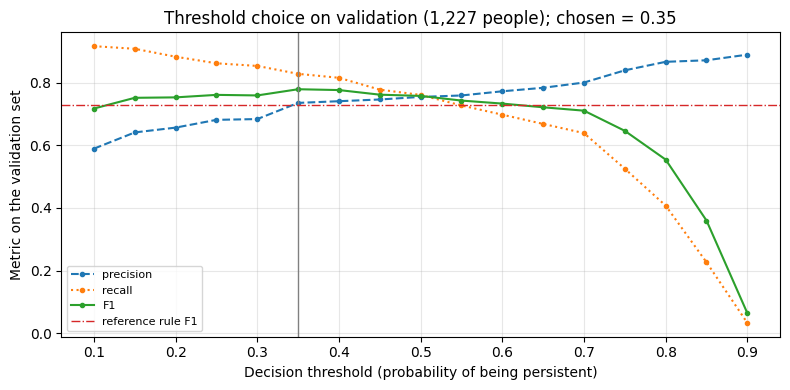

Validation set: model vs reference


,TP,FP,FN,TN,precision,recall,F1,accuracy
reference rule,171.000,61.000,67.000,928.000,0.737,0.718,0.728,0.896
"logistic, threshold 0.50",181.000,59.000,57.000,930.000,0.754,0.761,0.757,0.905
"logistic, threshold 0.35",197.000,71.000,41.000,918.000,0.735,0.828,0.779,0.909


In [12]:
# 3.3 THRESHOLD CHOSEN ON VALIDATION (TEST NOT USED)
X_val = val_c2[VARS_NUM + VARS_CAT]
p_val = modelo.predict_proba(X_val)[:, 1]
UMBRALES = np.round(np.arange(0.10, 0.901, 0.05), 2)

barrido = pd.DataFrame([metricas(y_val, (p_val >= u).astype(int), u) for u in UMBRALES])
barrido.index.name = "threshold"
mejor = barrido.sort_values(["F1", "recall"], ascending=False).index[0]
UMBRAL_DECISION = float(mejor)
print(f"Threshold chosen on validation: {UMBRAL_DECISION:.2f} (validation F1 = {barrido.loc[mejor, 'F1']:.3f})")
display(barrido[["precision", "recall", "F1"]].round(3).T)

fig, ax = plt.subplots(figsize=(8, 4))
for col, est in [("precision", "--"), ("recall", ":"), ("F1", "-")]:
    ax.plot(barrido.index, barrido[col], est, marker="o", markersize=3, label=col)
ax.axvline(UMBRAL_DECISION, color="grey", linewidth=1)
ax.axhline(resultados_val.iloc[0]["F1"], color="tab:red", linewidth=1, linestyle="-.", label="reference rule F1")
ax.set_xlabel("Decision threshold (probability of being persistent)")
ax.set_ylabel("Metric on the validation set")
ax.set_title(f"Threshold choice on validation ({len(val_c2):,} people); chosen = {UMBRAL_DECISION:.2f}")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIG_DIR / "c2_threshold_validation.png", dpi=150)
plt.show()

# model vs reference on the SAME validation people
resultados_val = pd.DataFrame([
    metricas(y_val, pred_ref_val, "reference rule"),
    metricas(y_val, (p_val >= 0.5).astype(int), "logistic, threshold 0.50"),
    metricas(y_val, (p_val >= UMBRAL_DECISION).astype(int), f"logistic, threshold {UMBRAL_DECISION:.2f}"),
])
print("Validation set: model vs reference")
resultados_val.round(3)

## 4. Final evaluation on the test set

### 4.1 Frozen choices, then one evaluation

Everything is now fixed: the features, the cohort, the training fit, the reference rule and the threshold chosen on validation. The test set (`prueba`) is used **once** here, and its results are not used to change anything.

*Note on the test set.* In W2 the descriptive persistence rates of these test people were compared with training (W2 section 6.4). No C2 choice uses the test set. However, W1–W2 explored all people, so the test set is not completely "blind" for the project's definitions (75% threshold, minimum months).

Test set: 1,192 people, 204 persistent (17.1%). Threshold fixed on validation: 0.35

Confusion matrix: logistic regression (final model)


,Predicted: persistent,Predicted: not persistent
Actual: persistent,170,34
Actual: not persistent,86,902


Confusion matrix: reference rule


,Predicted: persistent,Predicted: not persistent
Actual: persistent,155,49
Actual: not persistent,62,926


Test-set metrics (positive class = persistent):


,TP,FP,FN,TN,precision,recall,F1,accuracy
reference rule,155.000,62.000,49.000,926.000,0.714,0.760,0.736,0.907
logistic regression (threshold 0.35),170.000,86.000,34.000,902.000,0.664,0.833,0.739,0.899
always 'not persistent',0.000,0.000,204.000,988.000,0.000,0.000,0.000,0.829
difference (model − reference),15.000,24.000,-15.000,-24.000,-0.050,0.074,0.003,-0.008


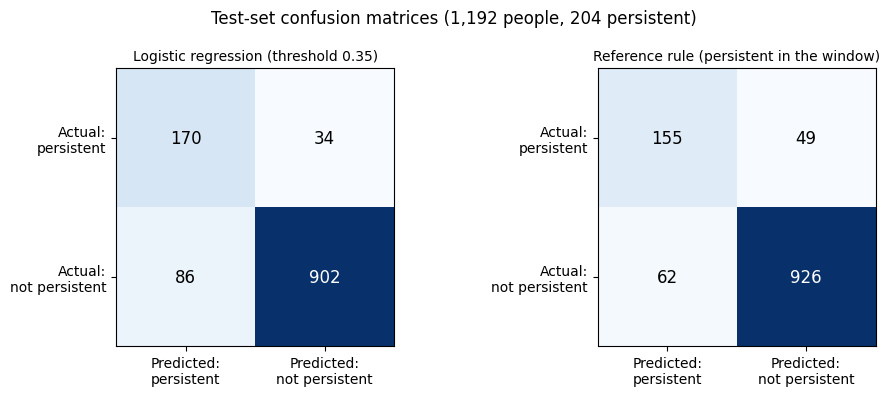

In [13]:
# 4.1 FINAL EVALUATION: MODEL AND REFERENCE ON THE SAME TEST PEOPLE (RUN ONCE)
prueba_c2 = datos_c2[datos_c2["conjunto"] == "prueba"]
y_test = prueba_c2[OBJETIVO]
p_test = modelo.predict_proba(prueba_c2[VARS_NUM + VARS_CAT])[:, 1]
pred_modelo_test = (p_test >= UMBRAL_DECISION).astype(int)
pred_ref_test = regla_referencia(prueba_c2)

print(f"Test set: {len(prueba_c2):,} people, {y_test.sum()} persistent ({y_test.mean():.1%}). "
      f"Threshold fixed on validation: {UMBRAL_DECISION:.2f}")
print("\nConfusion matrix: logistic regression (final model)")
display(tabla_confusion(y_test, pred_modelo_test))
print("Confusion matrix: reference rule")
display(tabla_confusion(y_test, pred_ref_test))

resultados_test = pd.DataFrame([
    metricas(y_test, pred_ref_test, "reference rule"),
    metricas(y_test, pred_modelo_test, f"logistic regression (threshold {UMBRAL_DECISION:.2f})"),
    metricas(y_test, np.zeros(len(y_test), dtype=int), "always 'not persistent'"),
])
resultados_test.loc["difference (model − reference)"] = resultados_test.iloc[1] - resultados_test.iloc[0]
print("Test-set metrics (positive class = persistent):")
display(resultados_test.round(3))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (titulo, pred) in zip(axes, [(f"Logistic regression (threshold {UMBRAL_DECISION:.2f})", pred_modelo_test),
                                     ("Reference rule (persistent in the window)", pred_ref_test)]):
    m = tabla_confusion(y_test, pred)
    ax.imshow(m.values, cmap="Blues")
    for (i, j), v in np.ndenumerate(m.values):
        ax.text(j, i, f"{v:,}", ha="center", va="center", fontsize=12,
                color="white" if v > m.values.max() / 2 else "black")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Predicted:\npersistent", "Predicted:\nnot persistent"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["Actual:\npersistent", "Actual:\nnot persistent"])
    ax.set_title(titulo, fontsize=10)
fig.suptitle(f"Test-set confusion matrices ({len(prueba_c2):,} people, {y_test.sum()} persistent)")
plt.tight_layout()
plt.savefig(FIG_DIR / "c2_confusion_test.png", dpi=150)
plt.show()

### 4.2 Reading the errors

**Positive class:** persistent in year 2 (overtime in ≥ 75% of the person's months). Test set: 1,192 people, of whom 204 are persistent (17.1%).

- **What the model gains and pays.** The logistic regression finds **170 of the 204** persistent people (recall 0.833), against 155 for the reference rule (0.760): 15 more people correctly flagged. In exchange it raises **24 more false alarms** (86 vs 62), so its precision is lower (0.664 vs 0.714). The two effects cancel out in F1: **0.739 vs 0.736**.
- **Consequence of a false positive.** A person, and the position behind them, is flagged for a staffing review although their overtime would not have persisted. The cost is review time, and possibly an unnecessary reorganisation or hire.
- **Consequence of a false negative.** A person who will keep receiving overtime is not reviewed. For one more year the service keeps paying overtime with its 25%–50% surcharge, and the fatigue risk continues.
- **Why the threshold is 0.35, not 0.5.** Only 17%–19% of people are persistent, so the model's probabilities rarely exceed 0.5. The validation rule chose 0.35, which favours recall. In management terms, missing a persistent case is treated as at least as costly as reviewing an extra one.
- **Why accuracy alone is not enough.** Predicting "nobody is persistent" reaches 0.829 accuracy on test while finding none of the 204 people. The reference rule even has slightly higher accuracy than the model (0.907 vs 0.899) because it flags fewer people. Accuracy rewards the majority class and hides the trade-off that matters for the decision.

## 5. Interpretation

**What the results show.**
- **Past persistence is the dominant signal.** In the model, one standard deviation more of "% of months with overtime" in the feature window multiplies the odds of being persistent by about 6 (odds ratio 5.9). That is why the one-variable reference rule is already strong (test F1 0.736).
- **The model does not clearly beat the rule in F1.** On validation it looked better (F1 0.779 vs 0.728), but on test the difference almost disappears (0.739 vs 0.736). With about 200–240 persistent people per set, a difference of this size is within normal sampling variation. **We do not claim that the model predicts better than the rule.**

**What the model adds.**
- A **different trade-off**: more of the persistent people are found (83% vs 76% recall), at the cost of more false alarms.
- A **probability for each person**. Management can rank people and positions, and move the threshold according to how many reviews it can actually carry out.
- **Context from other variables.** Holding past persistence fixed, being entitled to overtime raises the odds (OR 1.9), while professionals and technicians (OR ≈ 0.63) and the Sur service (OR 0.46) have lower odds. These are associations, not causes.

**One important limit.** There is **only one decision date** (1 September 2025) and one year to predict. We cannot check whether the model works for another year, for example after a change in rules such as Dictamen E121666. Other limits:
- people are identified only by name;
- the payroll records the month paid, not the month worked;
- the 598 people of the cohort who left or stayed under 6 months could not be evaluated;
- the test set was already seen descriptively in W2.

**One possible improvement.** Choose the threshold with **explicit costs** instead of F1. The payroll already contains the overtime amounts, so the cost of a false negative (one more year of overtime) can be estimated in CLP and compared with the cost of a review. When the 2026–2027 payroll is published, add a second cohort and validate across years (training on one year, testing on the next).

**A useful prediction does not prove that an action works.** Flagging likely persistent people does not show that a staffing review or a new hire would reduce their overtime. Testing that would need an intervention with a comparison group, for example piloting reviews in some flagged units and not in others (A/B-testing class). Operationally, flags should be aggregated by position and unit, not used to judge individuals.

## 6. Contributions and AI use

**Contributions.**
- **José Saavedra:** C2 dataset (features, target), reuse of the W2 split, evaluation functions, reference rule, and the logistic regression pipeline (sections 1.1–3.1).
- **Alessandro Lavezzi:** response to the W2 feedback (decision-date cohort, gap month, name matches across services), coefficients, threshold choice on validation, final test evaluation and interpretation (sections 1.0, 1.2, 3.2–5). Brief and presentation.
- Both members reviewed the whole notebook and the results quoted in the brief and the slides.

**AI use.** We used an AI assistant (Claude, Anthropic, through Claude Code) to draft and refactor code for sections 1.0–4 and to draft explanatory text. We checked and complemented its suggestions in three ways:
- we ran the notebook from top to bottom;
- we verified the metric functions on a hand-calculated example (section 2.1) and checked that preprocessing is fitted only on training (section 3.1);
- we compared every number quoted in the text, the brief and the slides with the saved outputs.

The team is responsible for the choices of task, cohort, features, threshold rule and interpretation.